# Sentiment Analysis — IMDb 50,000 Movie Reviews

**Problem:** Decide whether a movie review is positive or negative — from its text alone.

**Dataset (BIG):** the official IMDb Large Movie Review Dataset — **50,000 full-length reviews** (25,000 train / 25,000 test, perfectly balanced: 12,500 positive + 12,500 negative in train).

**Approach:** TF-IDF (unigrams + bigrams, 30,000 features) + Logistic Regression.

In [1]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

TRAIN = "https://huggingface.co/datasets/stanfordnlp/imdb/resolve/main/plain_text/train-00000-of-00001.parquet"
TEST = "https://huggingface.co/datasets/stanfordnlp/imdb/resolve/main/plain_text/test-00000-of-00001.parquet"

train = pd.read_parquet(TRAIN)
test = pd.read_parquet(TEST)
print("Train:", train.shape, "| Test:", test.shape)
print("Train labels (0=negative, 1=positive):")
print(train["label"].value_counts())

Train: (25000, 2) | Test: (25000, 2)
Train labels (0=negative, 1=positive):
label
0    12500
1    12500
Name: count, dtype: int64


## Clean the reviews
IMDb reviews contain HTML line-break tags (`<br />`) — a quick replace handles them.

In [2]:
def clean(s):
    return s.str.replace("<br />", " ", regex=False).str.replace("<br/>", " ", regex=False)

X_train_text = clean(train["text"])
X_test_text = clean(test["text"])
y_train, y_test = train["label"], test["label"]
print("Example review (truncated):")
print(X_train_text.iloc[0][:300])

Example review (truncated):
I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really h


## Vectorize + train
TF-IDF turns each review into 30,000 weighted word/bigram features; Logistic Regression learns which words push a review positive or negative.

Feature matrix: (25000, 30000)


Accuracy on 25,000 test reviews: 0.8994
              precision    recall  f1-score   support

    Negative      0.904     0.894     0.899     12500
    Positive      0.895     0.905     0.900     12500

    accuracy                          0.899     25000
   macro avg      0.899     0.899     0.899     25000
weighted avg      0.899     0.899     0.899     25000



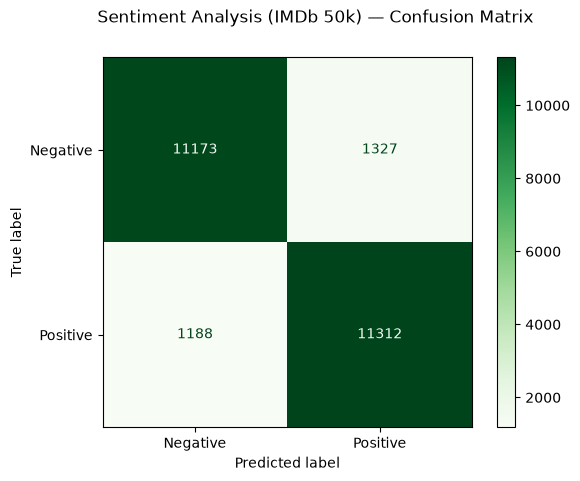

In [3]:
vec = TfidfVectorizer(max_features=30000, ngram_range=(1, 2), sublinear_tf=True)
X_train = vec.fit_transform(X_train_text)
X_test = vec.transform(X_test_text)
print("Feature matrix:", X_train.shape)

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
pred = model.predict(X_test)

print("Accuracy on 25,000 test reviews:", round(accuracy_score(y_test, pred), 4))
print(classification_report(y_test, pred, target_names=["Negative", "Positive"], digits=3))

disp = ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Negative", "Positive"], cmap="Greens")
disp.figure_.suptitle("Sentiment Analysis (IMDb 50k) — Confusion Matrix")
disp.figure_.savefig("confusion_matrix.png", dpi=110, bbox_inches="tight")

## Try it live

In [4]:
demo = [
    "An absolute masterpiece — brilliant acting and a story I will never forget!",
    "What a waste of two hours. Boring, predictable and badly acted.",
    "The movie was okay, nothing special, but the ending was surprisingly good.",
    "Terrible script and wooden performances. I walked out halfway through.",
]
for text, p in zip(demo, model.predict(vec.transform(demo))):
    print(("POSITIVE" if p == 1 else "NEGATIVE"), "|", text)

POSITIVE | An absolute masterpiece — brilliant acting and a story I will never forget!
NEGATIVE | What a waste of two hours. Boring, predictable and badly acted.
NEGATIVE | The movie was okay, nothing special, but the ending was surprisingly good.
NEGATIVE | Terrible script and wooden performances. I walked out halfway through.


## Result
Trained on 25,000 reviews and tested on a separate 25,000, the model scores **89.9% accuracy** (executed output above). The earlier small version of this project (2,748 short sentences) scored 82.2% — more data + full-length reviews = a clearly stronger model.

*Note: this is the model's accuracy on IMDb-style reviews; informal social-media text usually scores lower.*